# Optimization Example with Constraints and Lagrange Multipliers

Computational Models

Step-by-step resolution example of a constrained optimization problem
using the **Lagrange Multipliers method** from two approaches: primal
and dual approach.

1.  Primal Problem ([KKT
    Conditions](https://en.wikipedia.org/wiki/Karush%E2%80%93Kuhn%E2%80%93Tucker_conditions)).
    We simultaneously solve the entire system of equations describing
    the intersection point between the objective function and the
    constraint.

    1.  We derive the Lagrangian function $\mathcal{L}(x,y,\lambda)$
        with respect to all its variables ($x$, $y$, and $\lambda$) and
        set them to zero.
    2.  We solve for the primal variables ($x$ and $y$) in terms of the
        multiplier ($\lambda$), substitute them into the constraint
        equation to find the numerical value of $\lambda^*$, and finally
        obtain the optimal point $(x^*, y^*)$. Interpretation: You
        tackle the problem directly by solving the simultaneous equation
        system that dictates the tangency point between the level curves
        of the objective function and the constraint.

2.  Dual Problem (Minimization of the Dual Function). We decompose the
    problem into two parts (as indicated by the dual problem
    $\min_\lambda \max_{x,y} \mathcal{L}$):

    1.  Inner maximization: analytically find how $x$ and $y$ behave as
        a function of $\lambda$ by maximizing the Lagrangian, which
        allows you to construct the dual function $g(\lambda)$.
    2.  Outer minimization: minimize the dual function $g(\lambda)$ with
        respect to $\lambda$ to find the optimal multiplier $\lambda^*$.

## 1. Problem Definition

Objective function to maximize:

$$f(x, y) = 16 - (x^2 + y^2)$$

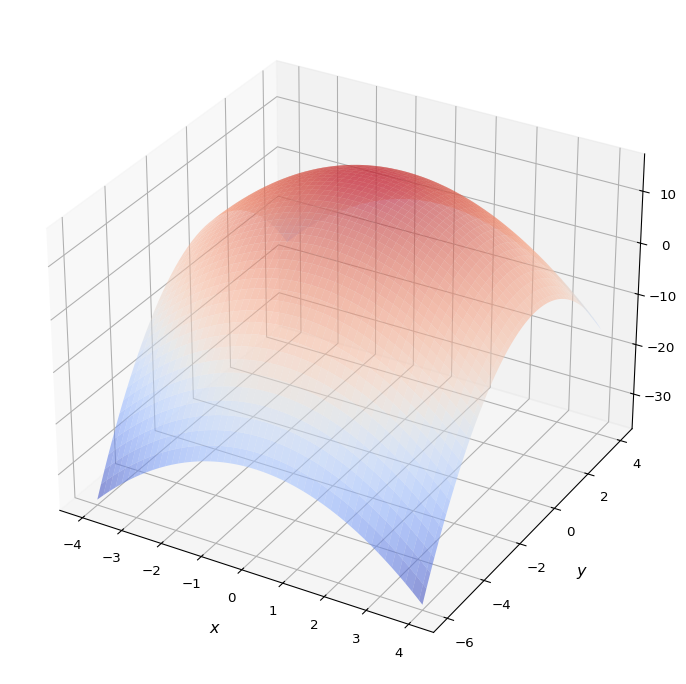

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# Create 3D figure
fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Full surface of the paraboloid f(x,y) = 16 - (x^2 + y^2)
x = np.linspace(-4, 4, 100)
y = np.linspace(-6, 4, 100)
X, Y = np.meshgrid(x, y)
Z = 16 - (X**2 + Y**2)

# Plot objective surface
surf = ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.55, edgecolor='none', antialiased=True)

# Axis labels and formatting
ax.set_xlabel('$x$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('$y$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('$z=f(x, y)$', fontsize=12, fontweight='bold', labelpad=10)


# Add color bar and legend
#fig.colorbar(surf, shrink=0.4, aspect=5, label='Value of f(x,y)')
#ax.legend(loc='upper left', fontsize=10)

plt.show()


Constraint function:

$$g(x, y) = 2x - y = 4 \implies 2x - y - 4 = 0$$

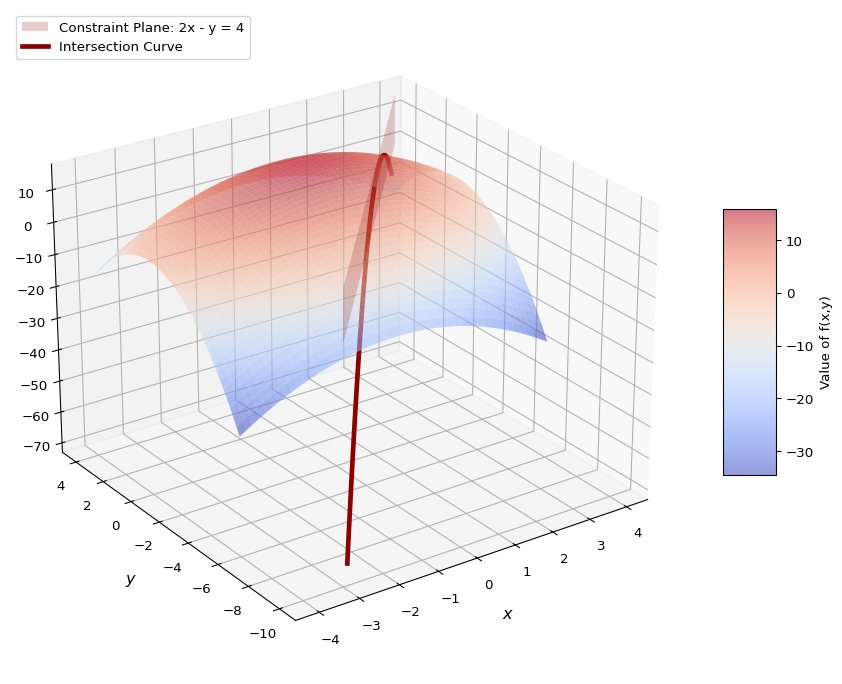

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Create 3D figure
fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Full surface of the paraboloid f(x,y) = 16 - (x^2 + y^2)
x = np.linspace(-4, 4, 100)
y = np.linspace(-6, 4, 100)
X, Y = np.meshgrid(x, y)
Z = 16 - (X**2 + Y**2)

# Plot objective surface
surf = ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.55, edgecolor='none', antialiased=True)

# 2. Transparent vertical plane for the constraint: 2x - y = 4 => y = 2x - 4
# Since the plane is vertical (independent of z), we use a mesh in X and Z.
x_plane = np.linspace(-3, 4, 50)
z_plane = np.linspace(0, 16, 50)
X_pl, Z_pl = np.meshgrid(x_plane, z_plane)
Y_pl = 2 * X_pl - 4

# Plot transparent constraint plane
ax.plot_surface(X_pl, Y_pl, Z_pl, color='red', alpha=0.2, edgecolor='none', label='Constraint Plane: 2x - y = 4')

# 3. Intersection curve (constraint projected onto the surface)
x_constr = np.linspace(-2.5, 3.5, 100)
y_constr = 2 * x_constr - 4
z_constr = 16 - (x_constr**2 + y_constr**2)
ax.plot(x_constr, y_constr, z_constr, color='darkred', linewidth=3.5, label='Intersection Curve')

# Axis labels and formatting
ax.set_xlabel('$x$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('$y$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('$z=f(x, y)$', fontsize=12, fontweight='bold', labelpad=10)


#ax.set_title('Surface, Constraint Plane, and Optimal Point (Lagrange)', fontsize=14, fontweight='bold')


# Add color bar and legend
fig.colorbar(surf, shrink=0.4, aspect=5, label='Value of f(x,y)')
ax.legend(loc='upper left', fontsize=10)

# Adjust camera perspective to appreciate the plane cutting the paraboloid
ax.view_init(elev=25, azim=-125)

plt.show()

Lagrangian function:

$$\mathcal{L}(x, y, \lambda) = 16 - (x^2 + y^2) + \lambda(2x - y - 4)$$

## 2. Primal Solution via Lagrange Multipliers

To find the critical points, we set the partial derivatives of
$\mathcal{L}(x, y, \lambda)$ to zero:

1.  Derivative with respect to $x$:

<span id="eq-dx">$$\frac{\partial \mathcal{L}}{\partial x} = -2x + 2\lambda = 0 \implies x = \lambda \qquad(1)$$</span>

1.  Derivative with respect to $y$:

<span id="eq-dy">$$\frac{\partial \mathcal{L}}{\partial y} = -2y - \lambda = 0 \implies y = -\frac{\lambda}{2} \qquad(2)$$</span>

1.  Derivative with respect to $\lambda$ (the original constraint):

<span id="eq-dlambda">$$\frac{\partial \mathcal{L}}{\partial \lambda} = 2x - y - 4 = 0 \qquad(3)$$</span>

### Substitution to find $\lambda$, $x$, and $y$:

We substitute $x = \lambda$ and $y = -\frac{\lambda}{2}$ into the
constraint from
<a href="#eq-dlambda" class="quarto-xref">Equation 3</a>:

$$2(\lambda) - \left(-\frac{\lambda}{2}\right) = 4$$

$$2\lambda + \frac{\lambda}{2} = 4$$

$$\frac{5\lambda}{2} = 4 \implies \lambda = \frac{8}{5} = 1.6$$

Now we calculate the optimal values for $x$ and $y$ in
<a href="#eq-dx" class="quarto-xref">Equation 1</a> and
<a href="#eq-dy" class="quarto-xref">Equation 2</a>:

-   $x^* = \frac{8}{5} = 1.6$
-   $y^* = -\frac{1}{2} \cdot \left(\frac{8}{5}\right) = -\frac{4}{5} = -0.8$

## 3. Resolution from the Dual Perspective

The dual problem is formulated as:

$$\min_{\lambda} g(\lambda) \quad \text{where} \quad g(\lambda) = \max_{x,y} \mathcal{L}(x, y, \lambda)$$

First, find the dual function
$g(\lambda) = \max_{x,y} \mathcal{L}(x, y, \lambda)$

We express $x$ and $y$ as functions of $\lambda$ that maximize
$\mathcal{L}$:

$$x(\lambda) = \lambda, \quad y(\lambda) = -\frac{\lambda}{2}$$

We substitute these values into the Lagrangian function
$\mathcal{L}(x, y, \lambda)$:

$$g(\lambda) = 16 - \left(\lambda^2 + \left(-\frac{\lambda}{2}\right)^2\right) + \lambda\left(2\lambda - \left(-\frac{\lambda}{2}\right) - 4\right)$$

$$g(\lambda) = 16 - \left(\lambda^2 + \frac{\lambda^2}{4}\right) + \lambda\left(\frac{5\lambda}{2} - 4\right)$$

$$g(\lambda) = 16 - \frac{5\lambda^2}{4} + \frac{5\lambda^2}{2} - 4\lambda$$

$$g(\lambda) = 16 + \frac{5\lambda^2}{4} - 4\lambda$$

Second, minimize the dual function $g(\lambda)$ over $\lambda$

To find the minimum of $g(\lambda)$, we derive with respect to $\lambda$
and set it to zero:

$$g'(\lambda) = \frac{5}{2}\lambda - 4 = 0 \implies \lambda^* = \frac{8}{5}$$

This gives us the same optimal values for $x^* = \frac{8}{5} = 1.6$ and
$y^* = -\frac{4}{5} = -0.8$

Since $g''(\lambda) = \frac{5}{2} > 0$, this point represents a **strict
minimum** for the dual function.

## 4. Final Result and Maximum Value

We evaluate the objective function $f(x, y)$ at the optimal point
$(x^*, y^*) = \left(\frac{8}{5}, -\frac{4}{5}\right)$:

$$f\left(\frac{8}{5}, -\frac{4}{5}\right) = 16 - \left(\left(\frac{8}{5}\right)^2 + \left(-\frac{4}{5}\right)^2\right)$$

$$f\left(\frac{8}{5}, -\frac{4}{5}\right) = 16 - \left(\frac{64}{25} + \frac{16}{25}\right)$$

$$f\left(\frac{8}{5}, -\frac{4}{5}\right) = 16 - \frac{80}{25} = 16 - 3.2 = 12.8$$

## Summary of the Solution and Why They Match:

-   **Optimal Point**: $(x^*, y^*) = (1.6, -0.8)$ or
    $\left(\frac{8}{5}, -\frac{4}{5}\right)$
-   **Optimal Lagrange Multiplier**: $\lambda^* = 1.6$ or $\frac{8}{5}$
-   **Maximum Value Achieved**: $f(x^*, y^*) = 12.8$ or $\frac{64}{5}$

The primal and dual solutions coincide because the objective function is
convex and the constraint is linear, which satisfies strong duality (the
duality gap is zero).More information at
<https://en.wikipedia.org/wiki/Duality_(optimization)>

## Solution Visualization

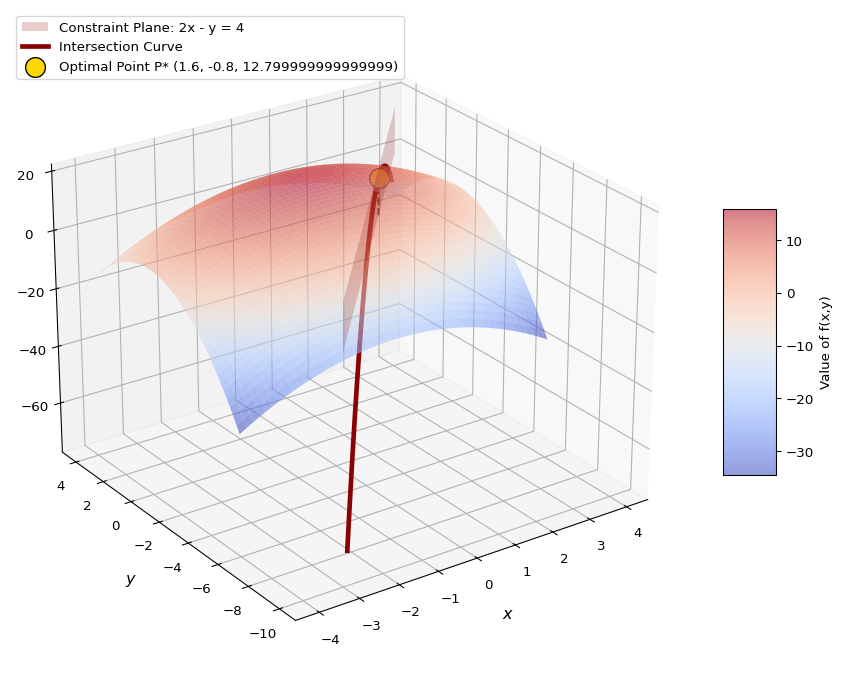

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Create 3D figure
fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Full surface of the paraboloid f(x,y) = 16 - (x^2 + y^2)
x = np.linspace(-4, 4, 100)
y = np.linspace(-6, 4, 100)
X, Y = np.meshgrid(x, y)
Z = 16 - (X**2 + Y**2)

# Plot objective surface
surf = ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.55, edgecolor='none', antialiased=True)

# 2. Transparent vertical plane for the constraint: 2x - y = 4 => y = 2x - 4
# Since the plane is vertical (independent of z), we use a mesh in X and Z.
x_plane = np.linspace(-3, 4, 50)
z_plane = np.linspace(0, 16, 50)
X_pl, Z_pl = np.meshgrid(x_plane, z_plane)
Y_pl = 2 * X_pl - 4

# Plot transparent constraint plane
ax.plot_surface(X_pl, Y_pl, Z_pl, color='red', alpha=0.2, edgecolor='none', label='Constraint Plane: 2x - y = 4')

# 3. Intersection curve (constraint projected onto the surface)
x_constr = np.linspace(-2.5, 3.5, 100)
y_constr = 2 * x_constr - 4
z_constr = 16 - (x_constr**2 + y_constr**2)
ax.plot(x_constr, y_constr, z_constr, color='darkred', linewidth=3.5, label='Intersection Curve')





# 4. Optimal point found: (1.6, -0.8, 12.8)
x_opt = 1.6
y_opt = -0.8
z_opt = 16 - (x_opt**2 + y_opt**2)

# Mark the optimal point
ax.scatter([x_opt], [y_opt], [z_opt], color='gold', s=220, zorder=5, edgecolors='black', label=f'Optimal Point P* ({x_opt}, {y_opt}, {z_opt})')

# Dashed line from the optimal point to the XY plane for visual reference
ax.plot([x_opt, x_opt], [y_opt, y_opt], [0, z_opt], color='black', linestyle='--', linewidth=1.5, alpha=0.7)

# Axis labels and formatting
ax.set_xlabel('$x$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('$y$', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('$z=f(x, y)$', fontsize=12, fontweight='bold', labelpad=10)


#ax.set_title('Surface, Constraint Plane, and Optimal Point (Lagrange)', fontsize=14, fontweight='bold')

# Add color bar and legend
fig.colorbar(surf, shrink=0.4, aspect=5, label='Value of f(x,y)')
ax.legend(loc='upper left', fontsize=10)

# Adjust camera perspective to appreciate the plane cutting the paraboloid
ax.view_init(elev=25, azim=-125)

plt.show()